In [1]:
import mnx

In [2]:
nscf = mnx.Bands.from_nscf(folder="/home/manex/bin/src/mnx/Tutorial/bands/CrSb/.", format="qe", mod=[36,36,36])

In [3]:
nscf.build_setup()

/home/manex/bin/venvs/new_mnx/lib/python3.10/site-packages/mnx/bands.py:1545: DeprecationWarning: dict interface is deprecated. Use attribute interface instead
  rotations = mag_dataset['rotations']


Non magnetic calculation.


# Fermi suface

In [7]:
meshes, bz_mesh = nscf.visualize_fsurface()

/home/manex/bin/venvs/new_mnx/lib/python3.10/site-packages/mnx/bands.py:1384: PyVistaDeprecationWarning: `n_faces_strict` is deprecated. Use `n_faces` instead, which now returns the number of polygonal faces.
  if filtered_fs.n_faces_strict > 0:


Widget(value='<iframe src="http://localhost:41067/index.html?ui=P_0x76dd78137e50_0&reconnect=auto" class="pyvi…

 JS Error => error: ResizeObserver loop completed with undelivered notifications.


One cuild obtain a publication ready Fermi surface, by increasing the k-grid with upsample (a fourier interpolation of the bands is performed, completly unphysical).

In [9]:
nscf_dense = mnx.Bands.from_nscf(folder="/home/manex/bin/src/mnx/Tutorial/bands/CrSb/.", format="qe", mod=[36,36,36], upsample=[3,3,3])

In [10]:
nscf_dense.build_setup()

/home/manex/bin/venvs/new_mnx/lib/python3.10/site-packages/mnx/bands.py:1545: DeprecationWarning: dict interface is deprecated. Use attribute interface instead
  rotations = mag_dataset['rotations']


Non magnetic calculation.


In [11]:
meshes_dense, bz_mesh_dense = nscf_dense.visualize_fsurface()

/home/manex/bin/venvs/new_mnx/lib/python3.10/site-packages/mnx/bands.py:1384: PyVistaDeprecationWarning: `n_faces_strict` is deprecated. Use `n_faces` instead, which now returns the number of polygonal faces.
  if filtered_fs.n_faces_strict > 0:


Widget(value='<iframe src="http://localhost:41067/index.html?ui=P_0x76dd86daec20_1&reconnect=auto" class="pyvi…

# Fermi planes

/home/manex/bin/venvs/new_mnx/lib/python3.10/site-packages/mnx/bands.py:1405: PyVistaFutureWarning: The default value of `algorithm` for the filter
`PolyData.extract_surface` will change in the future. It currently defaults to
`'dataset_surface'`, but will change to `None`. Explicitly set the `algorithm` keyword to
silence this warning.
  bz_mesh = pv.PolyData(bz_vertices, flat_faces).triangulate().extract_surface().clean()


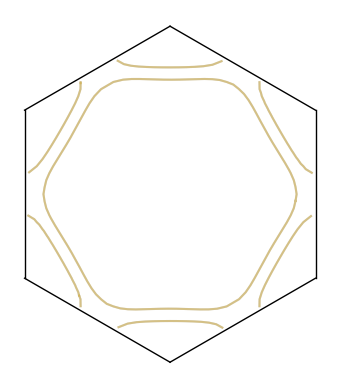

In [12]:
import matplotlib.pyplot as plt

f = plt.figure()
f1 = f.add_subplot()
contours_list = nscf.visualize_fp(f1,axis="ab",k=-0.5)

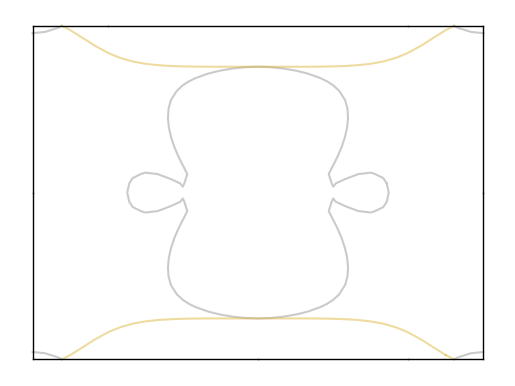

In [15]:
import matplotlib.pyplot as plt

f = plt.figure()
f1 = f.add_subplot()
contours_list = nscf.visualize_fp(f1,axis="ac",k=0) # Be carefull with the colors

# Nesting

In [4]:
import mnx

In [5]:
nscf = mnx.Bands.from_nscf(folder="/home/manex/bin/src/mnx/Tutorial/bands/CrSb/.", format="qe", mod=[36,36,36])

In [6]:
nscf.build_setup()

Non magnetic calculation.


In [7]:
nscf.get_Nsq(sigma=5e-2, downsample=(1,1,1))

In [8]:
k_inpath=[
        [[0,0,0],[0.5,0,0]],
        [[0.5,0,0],[0.33333,0.33333,0]],
        [[0.3333, 0.3333, 0], [0, 0, 0]],
        [[0, 0, 0], [0, 0, 0.5]],
        [[0,0,0.5],[0.5,0,0.5]],
        [[0.5,0,0.5],[0.33333,0.33333,0.5]],
        [[0.3333, 0.3333, 0.5], [0, 0, 0.5]],
        [[0, 0, 0.5], [0.25, 0, 0.5]],
        [[0.25, 0, 0.5], [0.25, 0, 0]]
    ]

xlabels = [r"$\Gamma$", "M", "K", r"$\Gamma$", "A", "L", "H", "A", "P", "Q"]

In [9]:
nesting, qpath, xticks = nscf.get_nesting_qpath(k_inpath, N=50, downsample=(1,1,1))

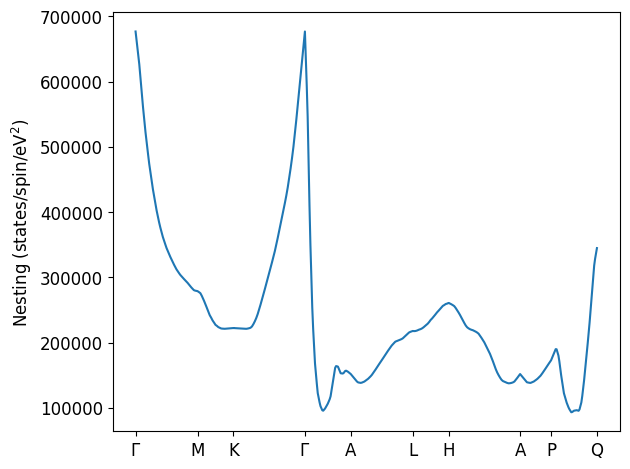

In [12]:
import matplotlib.pyplot as plt

f = plt.figure()
f1 = f.add_subplot(111)
f1.plot(qpath, nesting[0])
f1.set_xticks(xticks, xlabels)
f1.set_ylabel(r"Nesting (states/spin/eV$^2$)", fontsize=12)
f1.tick_params(labelsize=12)

f.tight_layout()


# Band resolved Lindhard susceptibility

In [1]:
import mnx

In [2]:
nscf = mnx.Bands.from_nscf(folder="/home/manex/bin/src/mnx/Tutorial/bands/CrSb/.", format="qe", mod=[36,36,36])

In [3]:
nscf.build_setup()

/home/manex/bin/venvs/new_mnx/lib/python3.10/site-packages/mnx/bands.py:1545: DeprecationWarning: dict interface is deprecated. Use attribute interface instead
  rotations = mag_dataset['rotations']


Non magnetic calculation.


Approximating the Lindhard susceptibility to 
$$\chi_{n\mathbf{k}}(0) = - \sum_m\sum_q \frac{f_{n\mathbf{k}}-f_{n\mathbf{q}}}{E_{n\mathbf{k}}-E_{m\mathbf{q}}}$$
we can understand the origin (in the band spectra) of the nesting, and consequently phonon softening.

In [24]:
nscf.get_Xnk(nmin=0, nmax=29, sigma=5e-2, downsample=[4,4,4])

In [25]:
k_inpath=[
        [[0,0,0],[0.5,0,0]],
        [[0.5,0,0],[0.33333,0.33333,0]],
        [[0.3333, 0.3333, 0], [0, 0, 0]],
        [[0, 0, 0], [0, 0, 0.5]],
        [[0,0,0.5],[0.5,0,0.5]],
        [[0.5,0,0.5],[0.33333,0.33333,0.5]],
        [[0.3333, 0.3333, 0.5], [0, 0, 0.5]],
        [[0, 0, 0.5], [0.25, 0, 0.5]],
        [[0.25, 0, 0.5], [0.25, 0, 0]]
    ]

xlabels = [r"$\Gamma$", "M", "K", r"$\Gamma$", "A", "L", "H", "A", "P", "Q"]

In [26]:
bands, qpath, xticks = nscf.get_bands(k_inpath, N=100)
xnk, qpath, xticks = nscf.get_Xnk_qpath(k_inpath, N=100, downsample=[4,4,4])

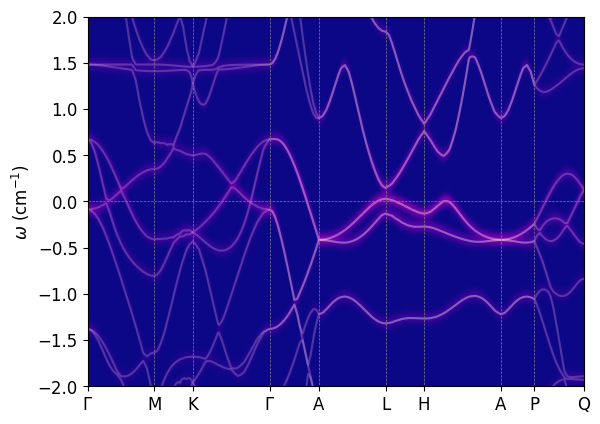

In [27]:
import matplotlib.pyplot as plt

f = plt.figure()
f1 = f.add_subplot(111)

ax, mmap, grid_x, grid_y = mnx.io.map_from_bands(f1, qpath, bands[0], xticks, xlabels, xnk[0], -2, 2, sigma=4e-2, vmax=5e4, bcolor="white")